# Tratamento dos dados NASA/POWER antes da analise Wavelet

Objetivo: preparar os arquivos CSV brutos horarios baixados do NASA/POWER e gerar uma base limpa, horaria e padronizada para a analise espectral.

## 1. Importacao das bibliotecas

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")

## 2. Configuracao dos caminhos

Coloque os CSV baixados do NASA/POWER dentro da pasta `dados_brutos_nasa_power`. O notebook vai ler todos os arquivos `.csv` encontrados nela.

In [2]:
pasta_projeto = Path(r"C:\Users\Windows\OneDrive\Documentos\Iniciação Cientifica - INPE\2026")
pasta_dados_brutos = pasta_projeto / "dados_brutos_nasa_power"
pasta_dados_tratados = pasta_projeto / "dados_tratados"
arquivo_saida = pasta_dados_tratados / "nasa_power_tratado.csv"

pasta_dados_brutos.mkdir(parents=True, exist_ok=True)
pasta_dados_tratados.mkdir(parents=True, exist_ok=True)

arquivos_csv = sorted(
    pasta_dados_brutos.glob("*.csv"),
    key=lambda arquivo: arquivo.stat().st_mtime,
    reverse=True
)

if not arquivos_csv:
    raise FileNotFoundError("Nenhum arquivo CSV encontrado em dados_brutos_nasa_power.")

arquivo_csv_mais_recente = arquivos_csv[0]
arquivo_csv_mais_recente

WindowsPath('C:/Users/Windows/OneDrive/Documentos/Iniciação Cientifica - INPE/2026/dados_brutos_nasa_power/POWER_Point_Hourly_20240501_20250501_022d67S_045d00W_LST.csv')

## 3. Leitura dos CSV e remocao do cabecalho NASA/POWER

Os arquivos do NASA/POWER podem vir com metadados antes da tabela. A funcao abaixo encontra automaticamente a linha que contem `YEAR` e uma estrutura temporal valida: `DOY` para dados diarios ou `MO`, `DY`, `HR` para dados horarios.

In [3]:
def encontrar_linha_cabecalho(caminho_csv):
    with open(caminho_csv, "r", encoding="utf-8") as arquivo:
        for numero_linha, linha in enumerate(arquivo):
            colunas = [coluna.strip() for coluna in linha.strip().split(",")]
            tem_formato_diario = "YEAR" in colunas and "DOY" in colunas
            tem_formato_horario = all(coluna in colunas for coluna in ["YEAR", "MO", "DY", "HR"])
            if tem_formato_diario or tem_formato_horario:
                return numero_linha
    raise ValueError(
        f"Nao encontrei cabecalho temporal valido em {caminho_csv.name}. "
        "Esperado: YEAR+DOY ou YEAR+MO+DY+HR."
    )


def ler_csv_nasa_power(caminho_csv):
    linha_cabecalho = encontrar_linha_cabecalho(caminho_csv)
    dados = pd.read_csv(caminho_csv, skiprows=linha_cabecalho)
    dados.columns = dados.columns.str.strip()
    dados["arquivo_origem"] = caminho_csv.name
    return dados


if not arquivos_csv:
    raise FileNotFoundError(
        "Nenhum CSV encontrado. Crie a pasta 'dados_brutos_nasa_power' "
        "e coloque nela os arquivos baixados do NASA/POWER."
    )
dados_brutos = ler_csv_nasa_power(arquivo_csv_mais_recente)

print(f"Arquivo lido: {arquivo_csv_mais_recente}")
print(f"Colunas encontradas: {list(dados_brutos.columns)}")
dados_brutos.head()

Arquivo lido: C:\Users\Windows\OneDrive\Documentos\Iniciação Cientifica - INPE\2026\dados_brutos_nasa_power\POWER_Point_Hourly_20240501_20250501_022d67S_045d00W_LST.csv
Colunas encontradas: ['YEAR', 'MO', 'DY', 'HR', 'T2M', 'RH2M', 'ALLSKY_SFC_SW_DWN', 'arquivo_origem']


,YEAR,MO,DY,HR,T2M,RH2M,ALLSKY_SFC_SW_DWN,arquivo_origem
0,2024,5,1,0,17.74,73.03,0.0,POWER_Point_Hourly_20240501_20250501_022d67S_0...
1,2024,5,1,1,17.06,75.24,0.0,POWER_Point_Hourly_20240501_20250501_022d67S_0...
2,2024,5,1,2,16.49,76.99,0.0,POWER_Point_Hourly_20240501_20250501_022d67S_0...
3,2024,5,1,3,16.01,78.51,0.0,POWER_Point_Hourly_20240501_20250501_022d67S_0...
4,2024,5,1,4,15.65,79.53,0.0,POWER_Point_Hourly_20240501_20250501_022d67S_0...


## 4. Conversao das colunas temporais para data e data_hora

Para dados horarios, o tempo da serie da Wavelet sera `data_hora`. Como a unidade do periodo sera dia, o passo temporal usado depois deve ser `dt = 1/24`.

In [4]:
dados = dados_brutos.copy()

colunas_tempo = ["YEAR", "DOY", "MO", "DY", "HR"]
for coluna in colunas_tempo:
    if coluna in dados.columns:
        dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")

if "DOY" in dados.columns:
    dados["data"] = pd.to_datetime(
        dados["YEAR"].astype("Int64").astype(str),
        format="%Y",
        errors="coerce",
    ) + pd.to_timedelta(dados["DOY"] - 1, unit="D")
    dados["data_hora"] = dados["data"]
elif all(coluna in dados.columns for coluna in ["YEAR", "MO", "DY", "HR"]):
    dados["data_hora"] = pd.to_datetime(
        dados.rename(columns={"YEAR": "year", "MO": "month", "DY": "day", "HR": "hour"})[
            ["year", "month", "day", "hour"]
        ],
        errors="coerce",
    )
    dados["data"] = dados["data_hora"].dt.floor("D")
else:
    raise KeyError("Formato temporal nao reconhecido. Esperado YEAR+DOY ou YEAR+MO+DY+HR.")

dados[[coluna for coluna in ["YEAR", "DOY", "MO", "DY", "HR", "data_hora", "data"] if coluna in dados.columns]].head()

,YEAR,MO,DY,HR,data_hora,data
0,2024,5,1,0,2024-05-01 00:00:00,2024-05-01
1,2024,5,1,1,2024-05-01 01:00:00,2024-05-01
2,2024,5,1,2,2024-05-01 02:00:00,2024-05-01
3,2024,5,1,3,2024-05-01 03:00:00,2024-05-01
4,2024,5,1,4,2024-05-01 04:00:00,2024-05-01


## 5. Renomeacao e selecao das variaveis

As variaveis sao padronizadas para nomes em `snake_case`, sem acentos, para facilitar o uso em codigo.

In [5]:
mapa_variaveis = {
    "T2M": "temperatura",
    "RH2M": "umidade_relativa",
    "ALLSKY_SFC_SW_DWN": "radiacao_onda_curta",
}

colunas_tempo_saida = [coluna for coluna in ["data", "data_hora", "YEAR", "DOY", "MO", "DY", "HR"] if coluna in dados.columns]
colunas_necessarias = [*colunas_tempo_saida, *mapa_variaveis.keys()]
colunas_ausentes = [coluna for coluna in colunas_necessarias if coluna not in dados.columns]

if colunas_ausentes:
    raise KeyError(f"Colunas ausentes no CSV: {colunas_ausentes}")

dados_tratados = (
    dados[colunas_necessarias]
    .rename(columns=mapa_variaveis)
    .sort_values("data_hora")
    .reset_index(drop=True)
)

dados_tratados.head()

,data,data_hora,YEAR,MO,DY,HR,temperatura,umidade_relativa,radiacao_onda_curta
0,2024-05-01,2024-05-01 00:00:00,2024,5,1,0,17.74,73.03,0.0
1,2024-05-01,2024-05-01 01:00:00,2024,5,1,1,17.06,75.24,0.0
2,2024-05-01,2024-05-01 02:00:00,2024,5,1,2,16.49,76.99,0.0
3,2024-05-01,2024-05-01 03:00:00,2024,5,1,3,16.01,78.51,0.0
4,2024-05-01,2024-05-01 04:00:00,2024,5,1,4,15.65,79.53,0.0


## 6. Substituicao de -999 por valores nulos

No NASA/POWER, o valor `-999` geralmente indica dado ausente ou invalido.

In [6]:
variaveis_ambientais = ["temperatura", "umidade_relativa", "radiacao_onda_curta"]

for coluna in variaveis_ambientais:
    dados_tratados[coluna] = pd.to_numeric(dados_tratados[coluna], errors="coerce")

dados_tratados = dados_tratados.replace(-999, np.nan)

dados_tratados.head()

,data,data_hora,YEAR,MO,DY,HR,temperatura,umidade_relativa,radiacao_onda_curta
0,2024-05-01,2024-05-01 00:00:00,2024,5,1,0,17.74,73.03,0.0
1,2024-05-01,2024-05-01 01:00:00,2024,5,1,1,17.06,75.24,0.0
2,2024-05-01,2024-05-01 02:00:00,2024,5,1,2,16.49,76.99,0.0
3,2024-05-01,2024-05-01 03:00:00,2024,5,1,3,16.01,78.51,0.0
4,2024-05-01,2024-05-01 04:00:00,2024,5,1,4,15.65,79.53,0.0


## 7. Verificacao de dados faltantes

In [7]:
resumo_faltantes = pd.DataFrame({
    "faltantes": dados_tratados.isna().sum(),
    "percentual_faltante": 100 * dados_tratados.isna().mean(),
})

resumo_faltantes

,faltantes,percentual_faltante
data,0,0.0
data_hora,0,0.0
YEAR,0,0.0
MO,0,0.0
DY,0,0.0
HR,0,0.0
temperatura,0,0.0
umidade_relativa,0,0.0
radiacao_onda_curta,0,0.0


## 8. Diagnostico da radiacao de onda curta

In [8]:
radiacao_bruta = pd.to_numeric(dados_brutos["ALLSKY_SFC_SW_DWN"], errors="coerce")
radiacao_tratada = dados_tratados["radiacao_onda_curta"]

print("Arquivo usado:", arquivo_csv_mais_recente.name)
print("\nRadiacao bruta no CSV:")
print(radiacao_bruta.describe())
print("Valores positivos no CSV bruto:", (radiacao_bruta > 0).sum())

print("\nRadiacao depois do tratamento:")
print(radiacao_tratada.describe())
print("Valores positivos depois do tratamento:", (radiacao_tratada > 0).sum())

dados_tratados[["data_hora", "HR", "radiacao_onda_curta"]].head(48)

Arquivo usado: POWER_Point_Hourly_20240501_20250501_022d67S_045d00W_LST.csv

Radiacao bruta no CSV:
count    8784.000000
mean      198.319291
std       275.538648
min         0.000000
25%         0.000000
50%         7.540000
75%       372.350000
max      1056.250000
Name: ALLSKY_SFC_SW_DWN, dtype: float64
Valores positivos no CSV bruto: 4579

Radiacao depois do tratamento:
count    8784.000000
mean      198.319291
std       275.538648
min         0.000000
25%         0.000000
50%         7.540000
75%       372.350000
max      1056.250000
Name: radiacao_onda_curta, dtype: float64
Valores positivos depois do tratamento: 4579


,data_hora,HR,radiacao_onda_curta
0,2024-05-01 00:00:00,0,0.00
1,2024-05-01 01:00:00,1,0.00
2,2024-05-01 02:00:00,2,0.00
3,2024-05-01 03:00:00,3,0.00
4,2024-05-01 04:00:00,4,0.00
5,2024-05-01 05:00:00,5,0.00
6,2024-05-01 06:00:00,6,20.38
7,2024-05-01 07:00:00,7,192.98
8,2024-05-01 08:00:00,8,402.70
9,2024-05-01 09:00:00,9,586.67


## 9. Conferencia de periodo, frequencia horaria e quantidade de registros

In [9]:
duplicatas_data_hora = dados_tratados.duplicated(subset="data_hora").sum()
print(f"Registros duplicados em data_hora: {duplicatas_data_hora}")

dados_tratados = dados_tratados.sort_values("data_hora").reset_index(drop=True)

periodo_inicio = dados_tratados["data_hora"].min()
periodo_fim = dados_tratados["data_hora"].max()
quantidade_registros = len(dados_tratados)
datas_esperadas = pd.date_range(periodo_inicio, periodo_fim, freq="h")
datas_faltantes = datas_esperadas.difference(dados_tratados["data_hora"])
intervalos = dados_tratados["data_hora"].diff().value_counts().sort_index()

print(f"Inicio: {periodo_inicio}")
print(f"Fim: {periodo_fim}")
print(f"Quantidade de registros: {quantidade_registros}")
print(f"Quantidade esperada em frequencia horaria: {len(datas_esperadas)}")
print(f"Horas faltantes na sequencia horaria: {len(datas_faltantes)}")
print("\nIntervalos encontrados entre registros:")
print(intervalos)

datas_faltantes[:10]

Registros duplicados em data_hora: 0
Inicio: 2024-05-01 00:00:00
Fim: 2025-05-01 23:00:00
Quantidade de registros: 8784
Quantidade esperada em frequencia horaria: 8784
Horas faltantes na sequencia horaria: 0

Intervalos encontrados entre registros:
data_hora
0 days 01:00:00    8783
Name: count, dtype: int64


DatetimeIndex([], dtype='datetime64[ns]', freq='h')

## 10. Graficos simples das series temporais

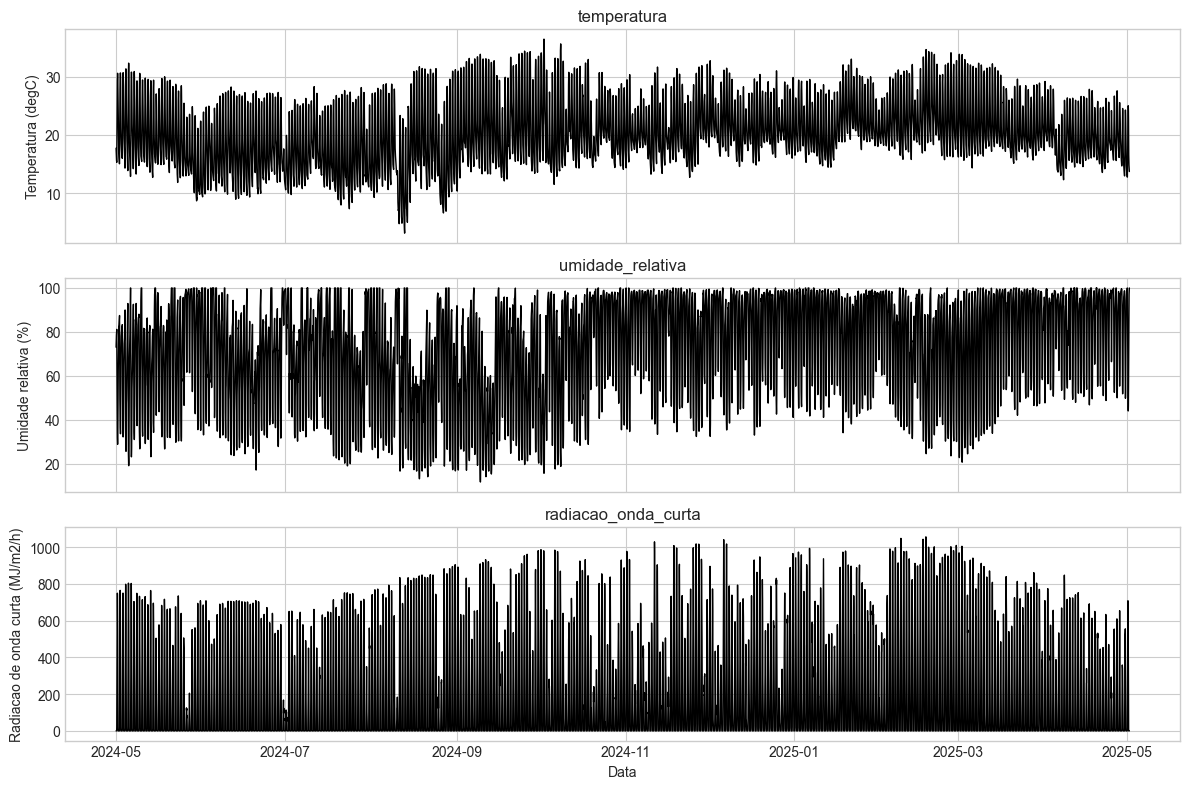

In [10]:
nomes_eixos = {
    "temperatura": "Temperatura (degC)",
    "umidade_relativa": "Umidade relativa (%)",
    "radiacao_onda_curta": "Radiacao de onda curta (MJ/m2/h)",
}

fig, eixos = plt.subplots(len(variaveis_ambientais), 1, figsize=(12, 8), sharex=True)

for eixo, coluna in zip(eixos, variaveis_ambientais):
    eixo.plot(dados_tratados["data_hora"], dados_tratados[coluna], color="black", linewidth=1)
    eixo.set_ylabel(nomes_eixos[coluna])
    eixo.set_title(coluna)

eixos[-1].set_xlabel("Data")
plt.tight_layout()
plt.show()

## 11. Salvamento da base tratada

A base final e salva em CSV para ser usada no notebook ou script da analise Wavelet.

In [11]:
dados_tratados.to_csv(arquivo_saida, index=False)

print(f"Arquivo salvo em: {arquivo_saida}")
dados_tratados.head()

Arquivo salvo em: C:\Users\Windows\OneDrive\Documentos\Iniciação Cientifica - INPE\2026\dados_tratados\nasa_power_tratado.csv


,data,data_hora,YEAR,MO,DY,HR,temperatura,umidade_relativa,radiacao_onda_curta
0,2024-05-01,2024-05-01 00:00:00,2024,5,1,0,17.74,73.03,0.0
1,2024-05-01,2024-05-01 01:00:00,2024,5,1,1,17.06,75.24,0.0
2,2024-05-01,2024-05-01 02:00:00,2024,5,1,2,16.49,76.99,0.0
3,2024-05-01,2024-05-01 03:00:00,2024,5,1,3,16.01,78.51,0.0
4,2024-05-01,2024-05-01 04:00:00,2024,5,1,4,15.65,79.53,0.0


## 12. Conferencia final da base pronta

In [12]:
dados_tratados.info()
dados_tratados.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   data                 8784 non-null   datetime64[ns]
 1   data_hora            8784 non-null   datetime64[ns]
 2   YEAR                 8784 non-null   int64         
 3   MO                   8784 non-null   int64         
 4   DY                   8784 non-null   int64         
 5   HR                   8784 non-null   int64         
 6   temperatura          8784 non-null   float64       
 7   umidade_relativa     8784 non-null   float64       
 8   radiacao_onda_curta  8784 non-null   float64       
dtypes: datetime64[ns](2), float64(3), int64(4)
memory usage: 617.8 KB


,data,data_hora,YEAR,MO,DY,HR,temperatura,umidade_relativa,radiacao_onda_curta
count,8784,8784,8784.000000,8784.000000,8784.000000,8784.000000,8784.000000,8784.000000,8784.000000
mean,2024-10-30 12:00:00,2024-10-30 23:30:00,2024.330601,6.521858,15.680328,11.500000,20.524408,71.555416,198.319291
min,2024-05-01 00:00:00,2024-05-01 00:00:00,2024.000000,1.000000,1.000000,0.000000,3.160000,11.660000,0.000000
25%,2024-07-31 00:00:00,2024-07-31 11:45:00,2024.000000,4.000000,8.000000,5.750000,16.380000,52.440000,0.000000
50%,2024-10-30 12:00:00,2024-10-30 23:30:00,2024.000000,7.000000,16.000000,11.500000,19.710000,76.660000,7.540000
75%,2025-01-30 00:00:00,2025-01-30 11:15:00,2025.000000,10.000000,23.000000,17.250000,24.920000,94.932500,372.350000
max,2025-05-01 00:00:00,2025-05-01 23:00:00,2025.000000,12.000000,31.000000,23.000000,36.450000,100.000000,1056.250000
std,NaN,NaN,0.470456,3.444255,8.818268,6.922581,5.705069,24.146196,275.538648
